In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas
import seaborn as sns
import json
%matplotlib inline
import  multiGP
import models_eccentric as models
import os

/root/miniconda3/envs/py39/lib/python3.9/site-packages/radvel/utils.py:1: DeprecationWarning: the imp module is deprecated in favour of importlib; see the module's documentation for alternative uses
  import imp


# Radial velocity plots

In [2]:
data_dir = "/home/datasets" # path datasets

In [3]:
df_all = pandas.read_csv(os.path.join(data_dir, "ESPRESSO/RV_data.txt"),  delim_whitespace=True)

df = df_all.dropna(subset=['rv_bart', 'rv_bart_err'])

t = df['bjd'] - 2457000

rv = df['rv_bart'] - np.mean(df['rv_bart'])
rv_err = df['rv_bart_err']

fwhm = df['fwhm_esp'] - np.mean(df['fwhm_esp'])
fwhm_err = df['fwhm_esp_err']

## Phase folded plot

In [4]:
# JSON parameters
# ===================
with open(os.path.join(data_dir, "best_fit_results_eccentric.json")) as f:
    data = json.load(f)

fp = data['fitted_parameters']

theta_best = [
    fp['t0']['median'],    
    fp['per']['median'],
    fp['h']['median'],
    fp['k']['median'],
    fp['krv']['median'],    
    fp['rv_gamma']['median'],   
    fp['lam']['median'],
    fp['prot']['median'],
    fp['w']['median'],
    fp['rv_scale']['median'],
    fp['fwhm_scale']['median'],
    fp['rv_dGdt_scale']['median'],
    fp['rv_jitter']['median'],
    fp['fwhm_jitter']['median'],
    fp['fwhm_gamma']['median'],
]


t0, per = theta_best[0], theta_best[1]
h, k     = theta_best[2], theta_best[3] 
krv, rv_gamma = theta_best[4], theta_best[5] 
lam, prot, w = theta_best[6], theta_best[7], theta_best[8] 
RV_scale, fwhm_scale = theta_best[9], theta_best[10]
RV_dGdt_scale = theta_best[11]  
rv_jitter   = theta_best[12] 
fwhm_jitter = theta_best[13] 
fwhm_gamma = theta_best[14]

# Hyperparameters GP
hp = multiGP.QPHyperParams(amp=1, lam=lam, P=prot, w=w)
A = np.array([RV_scale, fwhm_scale])
B = np.array([RV_dGdt_scale,  0.0])
jitter = np.array([rv_jitter, fwhm_jitter])

rvmodel = models.planetmodel(theta_best,t)

r_rv = rv - rvmodel
r_fwhm = fwhm - fwhm_gamma

t_list=[t,t]
r_list=[r_rv,r_fwhm]
err_list=[rv_err,fwhm_err]
t_rv = t

# Grid 
tgrid = np.linspace(t_rv.min(), t_rv.max(), 2000)
rvmodel_grid = models.planetmodel(theta_best, tgrid)


# ======================================
# GP prediction on grid
# ======================================

t_star_list = [tgrid, tgrid]

mu_list, sig_list = multiGP.gp_predict_multidim(
    t_list, r_list, err_list,
    t_star_list=t_star_list,
    A=A,
    B=B,
    hp=hp,
    jitter=jitter,
)

mu_rv_grid   = mu_list[0]
mu_fwhm_grid   = mu_list[1]

# ======================================
# GP prediction sui on observed time
# ======================================

mu_obs_list, _ = multiGP.gp_predict_multidim(
    t_list, r_list, err_list,
    t_star_list=t_list,
    A=A,
    B=B,
    hp=hp,
    jitter=jitter,
)

mu_rv_obs = mu_obs_list[0]


# Sinusoid
phase_grid = np.linspace(0,1,200)
t_sin = t0 + (phase_grid * per)
theta_sin = [t0, per, h, k, krv, rv_gamma]

sinusoid = models.planetmodel(theta_sin, t_sin) - rv_gamma

In [5]:
# Bin function
# ====================

def phase_bin(phase, rv, rv_err, n_bins=10):
    phase = np.asarray(phase) % 1.0
    rv = np.asarray(rv)
    rv_err = np.asarray(rv_err)
    
    bins = np.linspace(0, 1, n_bins + 1)
    digitized = np.digitize(phase, bins) - 1

    phase_binned, rv_binned, err_binned = [], [], []

    for i in range(n_bins):
        mask = digitized == i
        n_p = np.sum(mask)

        if n_p > 0:
            p_chunk = phase[mask]
            rv_chunk = rv[mask]
            err_chunk = rv_err[mask]

            w = 1.0 / (err_chunk**2)
            sum_w = np.sum(w)

            rv_mean = np.sum(w * rv_chunk) / sum_w
            phase_center = np.sum(w * p_chunk) / sum_w
    
            err_weights = np.sqrt(1.0 / sum_w)
            
            if n_p > 1:

                chi2_red = np.sum(w * (rv_chunk - rv_mean)**2) / (n_p - 1)
                std_error = err_weights * np.sqrt(max(1.0, chi2_red))
            else:
                std_error = err_chunk[0]

            phase_binned.append(phase_center)
            rv_binned.append(rv_mean)
            err_binned.append(std_error)

    return np.array(phase_binned), np.array(rv_binned), np.array(err_binned)


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


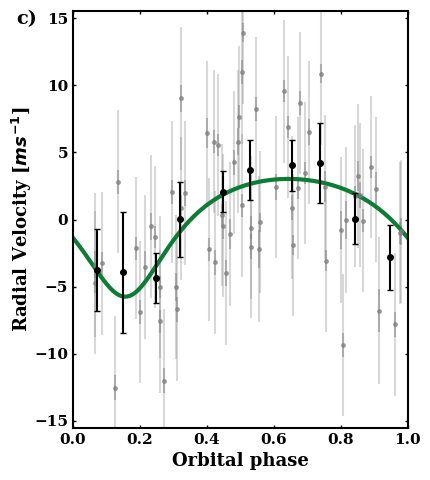

In [6]:
# Plot RV vs phase 
# ------------------------
colors = sns.color_palette("Greens", 10)  

fig = plt.figure(figsize=(4.5,5))
plt.rcParams.update({
    "font.size": 13,
    "font.family": "serif",
    'font.weight': 'bold',        # Bold standard text
    'axes.labelweight': 'bold',   # Bold X and Y labels
    'axes.titleweight': 'bold',   # Bold Title
    'figure.titleweight': 'bold',  # Bold Figure title
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    'mathtext.fontset': 'custom',
    'mathtext.bf': 'sans:bold',
    'mathtext.rm': 'sans',
})

phase_grid = np.linspace(0,1,200)
cadence_days = 50 / (24 * 60)   # days
bin_width = cadence_days / per

phase = ((t_rv - t0) / per) % 1
ph_bin, rv_bin, err_bin = phase_bin(phase, rv - mu_rv_obs, np.sqrt(rv_err**2 + rv_jitter**2))

plt.errorbar(phase, (rv - mu_rv_obs-rv_gamma)*1e3, yerr=(rv_err)*1e3, fmt='.', alpha=0.5, color='grey', label='Data')
plt.errorbar(phase, (rv - mu_rv_obs-rv_gamma)*1e3, yerr=(np.sqrt(rv_err**2 + rv_jitter**2))*1e3, fmt='.', alpha=0.3, color='grey', label='Data')
plt.errorbar(ph_bin, (rv_bin-rv_gamma)*1e3, yerr=err_bin*1e3, fmt="o", color='k', ms=4, label='Data binned', zorder=4, capsize=2)
plt.plot(phase_grid, sinusoid*1e3, color=colors[8], lw=3, label='Sinusoidal')

# plt.text(0.05,0.8,"$\mathrm{K_{RV}=3.29^{+1.00}_{-0.97}}$ m/s",fontsize=12,color='k',transform=plt.gca().transAxes)
plt.xlim(0.0, 1)
plt.ylim(-15.5, 15.5)
plt.xlabel("Orbital phase")
plt.ylabel("Radial Velocity [$ms^{-1}$]", labelpad=0)
# plt.legend(loc='upper left', ncol=1, fontsize=12)

ax = plt.gca()
for side in ['top', 'bottom', 'left', 'right']:
    ax.spines[side].set_linewidth(1.5)
    ax.spines[side].set_edgecolor('black')
ax.grid(False)
ax.set_facecolor('white')
ax.tick_params(axis='both', which='major', labelsize=11,
            width=1, length=2, color='black', direction='in', top=True, right=True)
# ax.yaxis.set_label_coords(-0.09, 0.5)
ax.text(-0.17, 0.97, 'c)', fontsize=14, transform=ax.transAxes)

plt.tight_layout()
# plt.savefig("/home/images/RV_plot.pdf")
plt.show()


## Recovery injection and distributions

In [7]:

data = np.load("/home/ymascolo/Desktop/projects/LHS6050/presentation_plot/transits+rv/dynesty_results.npz")
samples = data['flat_samples']

per = samples[:, 1] 
rp = samples[:, 2]
b = samples[:, 3]
h = samples[:, 4]
k = samples[:, 5]
mstar = samples[:, 6]
rstar = samples[:, 7]
krv = samples[:, 20]

a = ((per / 365.25)**(2/3) * mstar**(1/3))
a_rstar = (a * 215.032) / rstar

Rsun_to_Rearth = 109.076
Rp_Rearth = rp * rstar * Rsun_to_Rearth

e = h**2 + k**2
w = np.degrees(np.arctan2(h, k))

cosi = np.clip(b / a_rstar, -1.0, 1.0)
inc = np.degrees(np.arccos(cosi))
sini = np.sin(np.radians(inc))

G = 6.67430e-11
M_sun = 1.9885e30
day2sec = 86400
M_earth = 5.972e24
R_earth = 6.3781e6
teff_sun = 5778 

M_star = mstar * M_sun
per_sec = per * day2sec

Mp = ((krv * 1e3) * (np.sqrt(1 - (e**2))) * (M_star**(2/3)) * ((per_sec / (2 * np.pi * G))**(1/3))) / sini
Mpe = Mp / M_earth

rhoe = Mpe / (Rp_Rearth**3)
rho_cgs = rhoe * 5.51



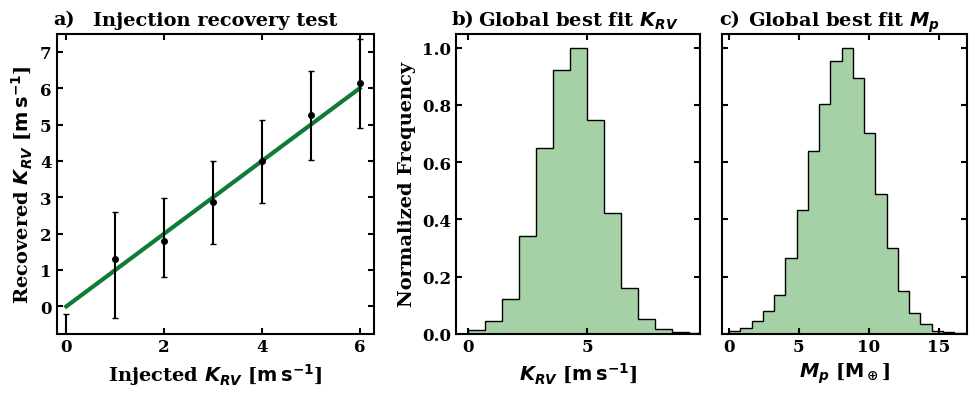

In [8]:
def get_weights(data, bins):
    counts, _ = np.histogram(data, bins=bins)
    return np.ones_like(data) / counts.max()

samples_to_plot = np.vstack([krv * 1e3, Mpe]).T

fig, axes = plt.subplots(1, 3, figsize=(10, 4), gridspec_kw={'width_ratios': [1.3, 1, 1]})

plt.rcParams.update({
    "font.size": 14,
    "font.family": "serif",
    'font.weight': 'bold',        # Bold standard text
    'axes.labelweight': 'bold',   # Bold X and Y labels
    'axes.titleweight': 'bold',   # Bold Title
    'figure.titleweight': 'bold',  # Bold Figure title
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    'mathtext.fontset': 'custom',
    'mathtext.bf': 'sans:bold',
    'mathtext.rm': 'sans',
})

for ax in axes:
    ax.set_facecolor('white')
    ax.tick_params(axis='both', which='major', labelsize=12, width=1.5, length=4)
    for side in ['top', 'bottom', 'left', 'right']:
        ax.spines[side].set_linewidth(1.5)
        ax.spines[side].set_edgecolor('black')
        ax.grid(False)

# --------Plot 3: recovery injection---------
x=[0, 1,2,3,4,5, 6]
y=[-1.42, 1.2929, 1.81, 2.88, 3.996, 5.26, 6.14]
yerr=[[1.3, 1.616, 0.99, 1.15, 1.143, 1.22, 1.24],\
      [1.2, 1.2992, 1.18, 1.12, 1.143, 1.22, 1.225]]
r=x
axes[0].errorbar(x, y, yerr=yerr,fmt="o", color='k', ms=4, zorder=4, capsize=2)


axes[0].plot(x, r, color=colors[8], lw=3)

axes[0].set_xlabel(r'Injected ${K_{RV}}$ [$\mathbf{m\,s^{-1}}$]', fontsize=14)
axes[0].set_ylabel(r'Recovered ${K_{RV}}$ [$\mathbf{m\,s^{-1}}$]', fontsize=14)
axes[0].set_xlim(-0.2, 6.3)
axes[0].set_ylim(-0.75, 7.5)
axes[0].set_title(r'Injection recovery test', fontsize=14)

axes[0].text(-0.01, 1.03, 'a)', fontsize=14, transform=axes[0].transAxes)


bins_n = 30
# -------Plot 1: krv --------
weights0 = get_weights(samples_to_plot[:, 0], bins_n)
axes[1].hist(samples_to_plot[:, 0], bins=bins_n, weights=weights0, 
       color='forestgreen', alpha=0.4, histtype='stepfilled', edgecolor='none')
axes[1].hist(samples_to_plot[:, 0], bins=bins_n, weights=weights0, 
             color='black', histtype='step', lw=1)

axes[1].set_xlabel(r'${K_{RV}}$ [$\mathbf{m\,s^{-1}}$]', fontsize=14)
axes[1].set_ylabel('Normalized Frequency',  fontsize=14)
axes[1].set_xlim(-0.5, 9.75)
axes[1].set_title(r'Global best fit ${K_{RV}}$', fontsize=14)

# axes[1].set_ylim(0.001, 1.1)

axes[1].text(-0.02, 1.03, 'b)', fontsize=14, transform=axes[1].transAxes)

# ---------Plot 2: Mpe-----------
weights1 = get_weights(samples_to_plot[:, 1], bins_n)
axes[2].sharey(axes[1])
plt.setp(axes[2].get_yticklabels(), visible=False)

axes[2].hist(samples_to_plot[:, 1], bins=bins_n, weights=weights1, 
             color='forestgreen', alpha=0.4, histtype='stepfilled', edgecolor='none')
axes[2].hist(samples_to_plot[:, 1], bins=bins_n, weights=weights1, 
             color='black', histtype='step', lw=1)
axes[2].set_title(r'Global best fit $M_p$',  fontsize=14)
axes[2].set_xlabel(r'$M_p$ [$\mathbf{M_\oplus}$]', fontsize=14)
axes[2].set_xlim(-0.5, 17)
axes[2].text(-0.01, 1.03, 'c)', fontsize=14, transform=axes[2].transAxes)

plt.subplots_adjust(wspace=0.08, left=0.1, right=0.95, bottom=0.15, top=0.9)

pos2 = axes[1].get_position()
axes[1].set_position([pos2.x0 + 0.06, pos2.y0, pos2.width, pos2.height])
pos2 = axes[2].get_position()
axes[2].set_position([pos2.x0 + 0.06, pos2.y0, pos2.width, pos2.height])

# plt.savefig('/home/images/hist.pdf', dpi=300, bbox_inches='tight')
plt.show()